# TraceText — AI vs Human Text Classification

**MLDS Mini Project**

**Aim:** Predict whether a passage is human-written or AI-generated using machine learning.

**Dataset:** RAID (`liamdugan/raid`) — the first run downloads a balanced subset; later runs can reuse `tracetext_sample.csv`.

**Labels:** `0 = Human`, `1 = AI-generated`.

**Project flow:** Dataset → EDA → Preprocessing → Classification → Clustering → Ensemble Models → Text Model Comparison → Final Model Export.

**Training-text rule:** Passages shorter than 50 words are excluded. Passages longer than 500 words are shortened to their first 500 words. These are our data-preparation choices, not hard limits of the classifier.

*Note: an AI-detection result is an estimate, not proof of who wrote a passage.*

## 1. Setup

In [1]:
%pip install -q datasets pandas numpy matplotlib scikit-learn joblib

In [2]:
import re
import string
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42

## 2. Load the dataset

We use human text and examples from 11 AI models. `source_id` is kept **only** to prevent related passages from appearing in both training and testing. We do not use the source model name as a prediction feature.

In [3]:
ai_models = [
    "chatgpt", "gpt4", "gpt3", "gpt2", "llama-chat", "mistral",
    "mistral-chat", "mpt", "mpt-chat", "cohere", "cohere-chat"
]

limits = {"human": 1980}
for name in ai_models:
    limits[name] = 180

data_file = Path("tracetext_sample.csv")

In [4]:
if data_file.exists():
    df = pd.read_csv(data_file)
else:
    from datasets import load_dataset

    counts = {name: 0 for name in limits}
    rows = []
    stream = load_dataset("liamdugan/raid", split="train", streaming=True)
    stream = stream.filter(lambda row: row["attack"] == "none")
    stream = stream.shuffle(seed=RANDOM_STATE, buffer_size=50000)

    for i, row in enumerate(stream):
        if i >= 1500000:
            break
        name = str(row["model"]).lower()
        text = row.get("generation") or ""
        if name not in limits or counts.get(name, 0) >= limits.get(name, 0):
            continue
        if len(text.split()) < 50:
            continue

        rows.append({"text": " ".join(text.split()[:500]),
                     "model": name, "domain": row.get("domain"),
                     "source_id": row.get("source_id")})
        counts[name] += 1
        if all(counts[name] == limits[name] for name in limits):
            break

    df = pd.DataFrame(rows)
    df.to_csv(data_file, index=False)

print("Dataset loaded:", df.shape)
display(df[["model", "domain"]].head())

README.md:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

Dataset loaded: (3960, 4)


,model,domain
0,mistral,abstracts
1,cohere,abstracts
2,gpt2,abstracts
3,mistral,abstracts
4,gpt2,abstracts


### Initial inspection and cleaning

Missing text/source IDs are removed. Exact duplicate passages are dropped. The model name is used **only** to create the binary target.

In [5]:
print("Missing values:")
display(df.isnull().sum())

print("Duplicate texts:", df["text"].duplicated().sum())
df = df.dropna(subset=["text", "source_id", "model"]).copy()
df["text"] = df["text"].astype(str).map(lambda text: " ".join(text.split()[:500]))
df = df[df["text"].str.split().str.len() >= 50].copy()
df = df.drop_duplicates(subset="text").reset_index(drop=True)
df["label"] = (df["model"] != "human").astype(int)

print("Final shape:", df.shape)
print("0 = Human, 1 = AI-generated")
display(df["label"].value_counts().sort_index())

Missing values:


,0
text,0
model,0
domain,0
source_id,0


Duplicate texts: 0
Final shape: (3960, 5)
0 = Human, 1 = AI-generated


,count
label,
0,1980
1,1980


## 3. EDA and feature extraction

We examine class balance and basic writing patterns. The numerical writing-style features will be used for the classroom algorithms.

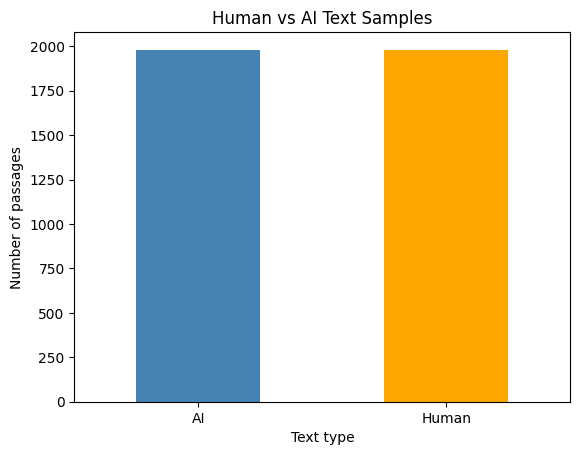

In [6]:
df["label"].map({0: "Human", 1: "AI"}).value_counts().plot(
    kind="bar", color=["steelblue", "orange"]
)
plt.title("Human vs AI Text Samples")
plt.xlabel("Text type")
plt.ylabel("Number of passages")
plt.xticks(rotation=0)
plt.show()

In [7]:
def get_features(text):
    words = text.split()
    sentences = [s for s in re.split(r"[.!?]+", text) if s.strip()]
    return pd.Series({
        "word_count": len(words),
        "char_count": len(text),
        "sentence_count": len(sentences),
        "avg_word_length": np.mean([len(w) for w in words]) if words else 0,
        "unique_word_ratio": len(set(w.lower() for w in words)) / max(len(words), 1),
        "punctuation_ratio": sum(ch in string.punctuation for ch in text) / max(len(text), 1)
    })

style = df["text"].apply(get_features)
df = pd.concat([df, style], axis=1)
features = list(style.columns)
display(df[features].describe().round(2))

,word_count,char_count,sentence_count,avg_word_length,unique_word_ratio,punctuation_ratio
count,3960.00,3960.00,3960.00,3960.00,3960.00,3960.00
mean,202.69,1320.28,9.52,5.67,0.63,0.02
std,108.23,644.17,6.04,0.72,0.14,0.02
min,50.00,263.00,1.00,3.45,0.04,0.00
25%,124.00,856.00,5.00,5.15,0.58,0.02
50%,174.00,1147.00,8.00,5.70,0.64,0.02
75%,242.00,1557.25,11.00,6.11,0.70,0.03
max,500.00,3520.00,54.00,18.10,1.00,0.41


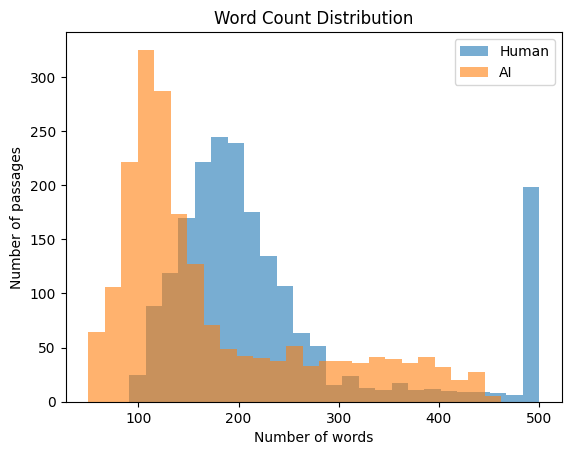

In [8]:
for label, name in [(0, "Human"), (1, "AI")]:
    values = df.loc[df["label"] == label, "word_count"]
    plt.hist(values, bins=25, alpha=0.6, label=name)

plt.title("Word Count Distribution")
plt.xlabel("Number of words")
plt.ylabel("Number of passages")
plt.legend()
plt.show()

## 4. Encoding, splitting and scaling

**Encoding:** The binary label is already encoded as 0/1. The `domain` column is one-hot encoded below as a lab demonstration, but it is **not used** to classify text: domain/source metadata may provide shortcuts instead of learning writing patterns.

**Preprocessing:** A median imputer handles missing numeric features if any occur, and StandardScaler standardizes them. Both are fitted on the **training data only**.

In [9]:
domain_encoded = pd.get_dummies(df["domain"], prefix="domain", dtype=int)
display(domain_encoded.head())

,domain_abstracts,domain_books
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0


In [10]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(df, df["label"], groups=df["source_id"]))

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()
y_train = train["label"]
y_test = test["label"]

print("Training:", train.shape, "Testing:", test.shape)
print("Shared source IDs:", len(set(train["source_id"]) & set(test["source_id"])))
display(pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()}).fillna(0))

Training: (3152, 11) Testing: (808, 11)
Shared source IDs: 0


,Train,Test
label,,
0,1577,403
1,1575,405


In [11]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train = imputer.fit_transform(train[features])
X_test = imputer.transform(test[features])
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Numerical features:", features)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Numerical features: ['word_count', 'char_count', 'sentence_count', 'avg_word_length', 'unique_word_ratio', 'punctuation_ratio']
Train shape: (3152, 6) Test shape: (808, 6)


## 5. Classification — Logistic Regression, KNN and Naive Bayes

All three models use the **same scaled writing-style features**, so their scores can be compared directly. Here, positive class (`1`) means AI-generated text.

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Gaussian Naive Bayes": GaussianNB()
}

results = []
predictions = {}

In [13]:
def scores(name, actual, predicted, feature_type):
    return {
        "Model": name,
        "Features": feature_type,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1": f1_score(actual, predicted, zero_division=0)
    }

for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    predictions[name] = predicted
    results.append(scores(name, y_test, predicted, "Writing style"))

display(pd.DataFrame(results).round(3))

,Model,Features,Accuracy,Precision,Recall,F1
0,Logistic Regression,Writing style,0.692,0.666,0.773,0.715
1,KNN,Writing style,0.844,0.874,0.805,0.838
2,Gaussian Naive Bayes,Writing style,0.783,0.779,0.793,0.786


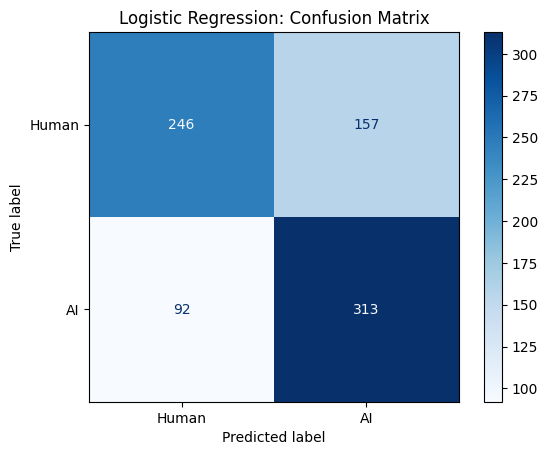

In [14]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions["Logistic Regression"],
    display_labels=["Human", "AI"], cmap="Blues"
)
plt.title("Logistic Regression: Confusion Matrix")
plt.show()

## 6. K-Means clustering

K-Means is **unsupervised**: it groups similar writing styles without using the human/AI labels. The elbow plot helps visualize how the within-cluster sum of squares (WCSS) changes with K. `K=3` is used for a small, interpretable demonstration; it is not claimed to be the unique optimal value.

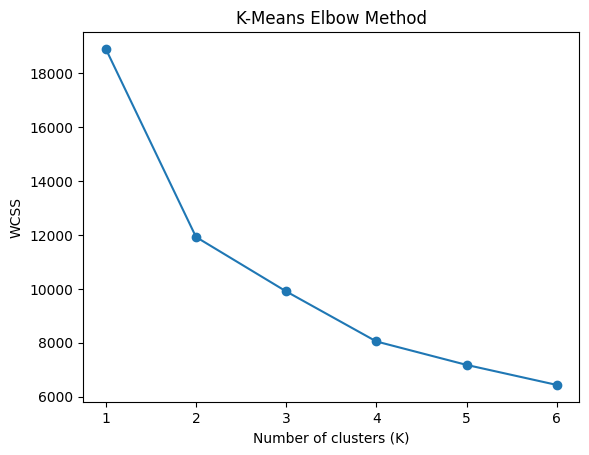

In [15]:
wcss = []
for k in range(1, 7):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_train)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 7), wcss, marker="o")
plt.title("K-Means Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS")
plt.show()

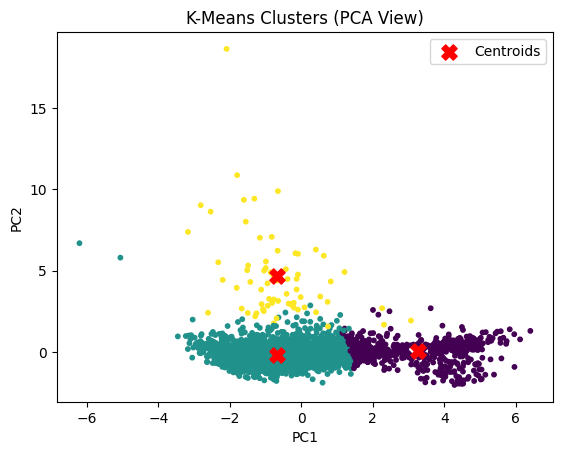

In [16]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_train)

pca = PCA(n_components=2, random_state=42)
points = pca.fit_transform(X_train)
centers = pca.transform(kmeans.cluster_centers_)

plt.scatter(points[:, 0], points[:, 1], c=kmeans_labels, s=10, cmap="viridis")
plt.scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=120, label="Centroids")
plt.legend()
plt.title("K-Means Clusters (PCA View)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [17]:
cluster_data = train[["label", "word_count", "avg_word_length"]].copy()
cluster_data["cluster"] = kmeans_labels

print("Cluster profile (labels used for interpretation only):")
display(cluster_data.groupby("cluster").agg(
    Samples=("label", "size"),
    AI_share=("label", "mean"),
    Mean_words=("word_count", "mean"),
    Mean_word_length=("avg_word_length", "mean")
).round(2))

Cluster profile (labels used for interpretation only):


,Samples,AI_share,Mean_words,Mean_word_length
cluster,,,,
0,536,0.46,396.71,5.13
1,2547,0.51,163.30,5.77
2,69,0.36,158.45,6.22


## 7. Gaussian Mixture Model (GMM)

GMM uses the Expectation-Maximization (EM) algorithm. Unlike K-Means, it gives **soft probabilities of belonging to each cluster**. These are **not** probabilities of AI authorship.

In [18]:
bic_results = []
for k in [3, 4, 5]:
    gmm = GaussianMixture(n_components=k, covariance_type="diag", random_state=42)
    gmm.fit(X_train)
    bic_results.append({"K": k, "BIC": gmm.bic(X_train)})

bic_table = pd.DataFrame(bic_results)
display(bic_table.round(2))
best_k = int(bic_table.loc[bic_table["BIC"].idxmin(), "K"])
print("Selected GMM clusters (lowest BIC):", best_k)

,K,BIC
0,3,38125.56
1,4,33292.58
2,5,31192.17


Selected GMM clusters (lowest BIC): 5


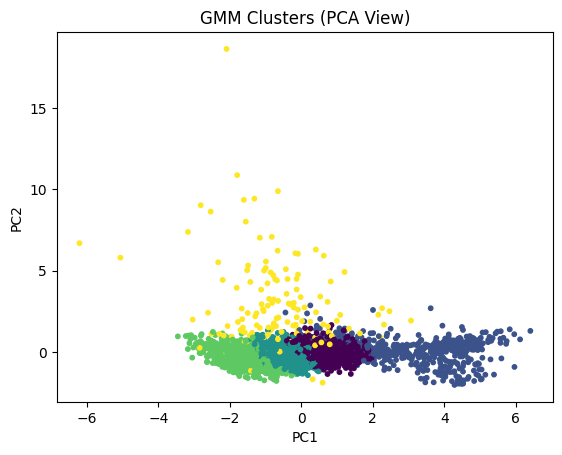

,0,1,2,3,4
0,0.0,0.0,0.0,0.999,0.001
1,0.0,0.0,0.0,1.000,0.000
2,0.0,0.0,0.0,0.999,0.001
3,0.0,1.0,0.0,0.000,0.000
4,0.0,0.0,0.0,1.000,0.000


In [19]:
gmm = GaussianMixture(n_components=best_k, covariance_type="diag", random_state=42)
gmm_labels = gmm.fit_predict(X_train)
probabilities = gmm.predict_proba(X_train)

plt.scatter(points[:, 0], points[:, 1], c=gmm_labels, s=10, cmap="viridis")
plt.title("GMM Clusters (PCA View)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

display(pd.DataFrame(probabilities).head().round(3))

## 8. Decision Tree, Bagging and Random Forest

We compare a single tree with a Bagging ensemble (50 trees), a Random Forest (100 trees), and a balanced Random Forest. **Class weighting does not always improve recall**; we check its actual effect on our dataset.

In [20]:
ensemble_models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=10, random_state=42),
        n_estimators=50, random_state=42, n_jobs=-1
    ),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Balanced Random Forest": RandomForestClassifier(
        n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1
    )
}

In [21]:
for name, model in ensemble_models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    predictions[name] = predicted
    results.append(scores(name, y_test, predicted, "Writing style"))

style_results = pd.DataFrame(results).sort_values("F1", ascending=False)
display(style_results.round(3))

,Model,Features,Accuracy,Precision,Recall,F1
4,Bagging,Writing style,0.861,0.875,0.844,0.859
6,Balanced Random Forest,Writing style,0.859,0.865,0.852,0.858
5,Random Forest,Writing style,0.856,0.866,0.844,0.855
3,Decision Tree,Writing style,0.848,0.877,0.810,0.842
1,KNN,Writing style,0.844,0.874,0.805,0.838
2,Gaussian Naive Bayes,Writing style,0.783,0.779,0.793,0.786
0,Logistic Regression,Writing style,0.692,0.666,0.773,0.715


### Bagging with different base estimators

Each ensemble below uses 20 estimators and the same scaled writing-style features. This lets us compare Bagging with a Decision Tree, KNN, and Logistic Regression base estimator.

In [22]:
bagging_base_models = {
    "Bagging + Decision Tree (20)": BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=10, random_state=42),
        n_estimators=20, random_state=42, n_jobs=-1
    ),
    "Bagging + KNN (20)": BaggingClassifier(
        estimator=KNeighborsClassifier(n_neighbors=5),
        n_estimators=20, random_state=42, n_jobs=-1
    ),
    "Bagging + Logistic Regression (20)": BaggingClassifier(
        estimator=LogisticRegression(max_iter=1000, random_state=42),
        n_estimators=20, random_state=42, n_jobs=-1
    )
}

bagging_base_results = []
for name, model in bagging_base_models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    bagging_base_results.append(scores(name, y_test, predicted, "Writing style"))

bagging_base_results = pd.DataFrame(bagging_base_results).sort_values("F1", ascending=False)
display(bagging_base_results.round(3))

,Model,Features,Accuracy,Precision,Recall,F1
0,Bagging + Decision Tree (20),Writing style,0.864,0.877,0.847,0.862
1,Bagging + KNN (20),Writing style,0.851,0.882,0.812,0.846
2,Bagging + Logistic Regression (20),Writing style,0.689,0.665,0.765,0.712


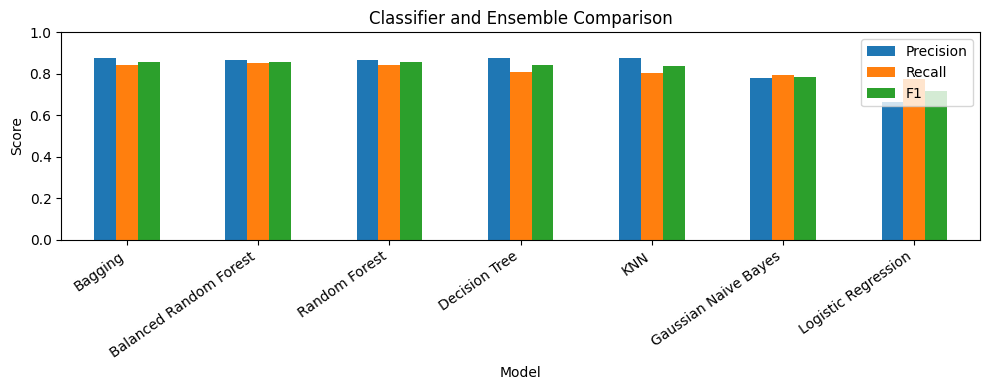

In [23]:
style_results.set_index("Model")[["Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(10, 4)
)
plt.title("Classifier and Ensemble Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 9. TF-IDF model comparison with grouped cross-validation

The same TF-IDF settings are used for each classifier. We compare Logistic Regression, Multinomial Naive Bayes, and SGD Classifier using **5-fold Stratified Group Cross-Validation on the training split only**. Grouping by `source_id` helps keep related passages in the same fold. The test split is kept separate until a model is selected.

In [24]:
text_models = {
    "TF-IDF + Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2)),
        ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
    ]),
    "TF-IDF + Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2)),
        ("classifier", MultinomialNB())
    ]),
    "TF-IDF + SGD Classifier": Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2)),
        ("classifier", SGDClassifier(
            loss="log_loss", max_iter=1000, tol=1e-3,
            class_weight="balanced", random_state=42
        ))
    ])
}

In [25]:
group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_rows = []
for name, model in text_models.items():
    cv_scores = cross_validate(
        model,
        train["text"],
        y_train,
        groups=train["source_id"],
        cv=group_cv,
        scoring=scoring,
        n_jobs=1
    )
    cv_rows.append({
        "Model": name,
        "Accuracy": cv_scores["test_accuracy"].mean(),
        "Precision": cv_scores["test_precision"].mean(),
        "Recall": cv_scores["test_recall"].mean(),
        "F1": cv_scores["test_f1"].mean(),
        "F1 Std": cv_scores["test_f1"].std()
    })

text_cv_results = pd.DataFrame(cv_rows).sort_values("F1", ascending=False).reset_index(drop=True)
display(text_cv_results.round(3))

best_text_name = text_cv_results.loc[0, "Model"]
print("Selected using mean grouped-CV F1:", best_text_name)

,Model,Accuracy,Precision,Recall,F1,F1 Std
0,TF-IDF + SGD Classifier,0.899,0.914,0.881,0.897,0.007
1,TF-IDF + Logistic Regression,0.883,0.877,0.890,0.883,0.006
2,TF-IDF + Multinomial Naive Bayes,0.736,0.672,0.917,0.775,0.010


Selected using mean grouped-CV F1: TF-IDF + SGD Classifier


### Held-out test evaluation

The selected classifier is now fitted on the training split and evaluated on the untouched test split. The test results are not used to choose between the TF-IDF classifiers.

,Model,Features,Accuracy,Precision,Recall,F1
7,TF-IDF + SGD Classifier,Text (TF-IDF),0.887,0.894,0.879,0.887
4,Bagging,Writing style,0.861,0.875,0.844,0.859
6,Balanced Random Forest,Writing style,0.859,0.865,0.852,0.858
5,Random Forest,Writing style,0.856,0.866,0.844,0.855
3,Decision Tree,Writing style,0.848,0.877,0.810,0.842
1,KNN,Writing style,0.844,0.874,0.805,0.838
2,Gaussian Naive Bayes,Writing style,0.783,0.779,0.793,0.786
0,Logistic Regression,Writing style,0.692,0.666,0.773,0.715


Selected TF-IDF model test report:
              precision    recall  f1-score   support

       Human       0.88      0.90      0.89       403
          AI       0.89      0.88      0.89       405

    accuracy                           0.89       808
   macro avg       0.89      0.89      0.89       808
weighted avg       0.89      0.89      0.89       808



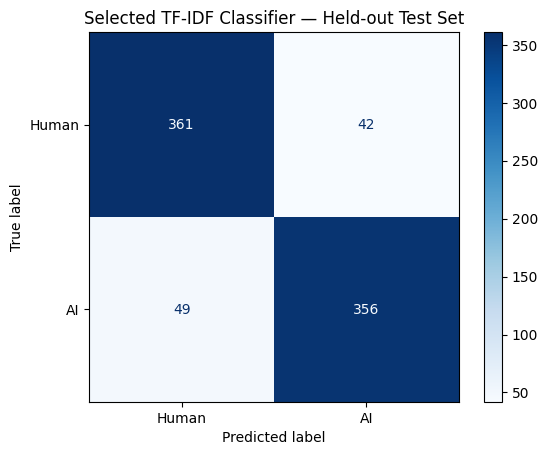

In [26]:
text_model = text_models[best_text_name]
text_model.fit(train["text"], y_train)
text_predictions = text_model.predict(test["text"])
results.append(scores(best_text_name, y_test, text_predictions, "Text (TF-IDF)"))

comparison = pd.DataFrame(results).sort_values("F1", ascending=False)
display(comparison.round(3))

print("Selected TF-IDF model test report:")
print(classification_report(y_test, text_predictions, target_names=["Human", "AI"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, text_predictions, display_labels=["Human", "AI"], cmap="Blues"
)
plt.title("Selected TF-IDF Classifier — Held-out Test Set")
plt.show()

## 10. Final model export and example prediction

After the held-out evaluation, the selected pipeline is refitted on **all eligible rows** so the exported model can learn from the full dataset. The earlier test metrics remain the held-out evaluation; do not treat predictions on the full training dataset as test performance. The exported pipeline includes TF-IDF and the selected classifier.

In [27]:
text_model.fit(df["text"], df["label"])
joblib.dump(text_model, "tracetext_model.joblib")
print("Saved: tracetext_model.joblib")
print("Final training rows:", len(df))

Saved: tracetext_model.joblib
Final training rows: 3960


In [28]:
example = (
    "Public libraries are adapting to new ways people find and use information. "
    "Many now provide digital borrowing, shared workspaces, and short training sessions "
    "alongside printed books. These services do not replace the traditional role of a library; "
    "they broaden it. A useful improvement is to ask visitors which resources they actually use "
    "and review those responses before making expensive changes."
)

probability_ai = text_model.predict_proba([example])[0][1]
predicted_label = "AI-generated" if probability_ai >= 0.5 else "Human-written"

print("Example word count:", len(example.split()))
print("Prediction:", predicted_label)
print("Estimated AI probability:", round(probability_ai * 100, 2), "%")

Example word count: 60
Prediction: AI-generated
Estimated AI probability: 66.02 %


## 11. Conclusion and practical coverage

| Topic learned in MLDS lab | Where it appears |
|---|---|
| Data loading, missing values, duplicates, EDA | Sections 2–3 |
| Encoding, numerical feature extraction, StandardScaler | Sections 3–4 |
| Logistic Regression, KNN, Gaussian Naive Bayes | Section 5 |
| K-Means, elbow method, cluster profiling | Section 6 |
| GMM, EM, soft cluster membership | Section 7 |
| Decision Tree, Bagging, Random Forest, class weights | Section 8 |
| Bagging with Decision Tree, KNN, and Logistic Regression base estimators | Section 8 |
| TF-IDF classifier comparison using grouped 5-fold cross-validation | Section 9 |
| Accuracy, Precision, Recall, F1, confusion matrix | Sections 5, 8–9 |
| Final pipeline refit on all eligible rows and model export | Section 10 |

**Model-selection note:** The TF-IDF classifiers use the same representation and fixed settings. We compare their mean F1 across 5 grouped folds; this is cross-validation, not hyperparameter tuning. The selected model is evaluated on the held-out test split before the final export is refitted on all eligible data.

**Not included:** Simple/Multiple Linear Regression, MAE, MSE, RMSE and R². These are usually used for continuous targets, while TraceText predicts a **binary class**. Applying regression to 0/1 labels only to tick a syllabus box would make the project harder to justify.

**Viva summary:** Data was cleaned, encoded, split by source ID, and scaled for the writing-style models. Classifiers and bagging variants were compared, and K-Means and GMM were used to explore writing-style groups. The text classifiers share the same TF-IDF setup and are compared using grouped cross-validation. The selected pipeline is evaluated on held-out data and then refitted on all eligible rows for export. **A prediction is not proof that a passage was AI-written.**